Now that I ran Octopus on a dozen of machines of Top500.org, I would like to report this to IT4I. 
For this, we need to build an observation of computer time efficiency for all the runs we have. 

In [1]:
import pandas as pd
import octopus_slabs
from octopus_slabs.Libs.libPlotting import IndexFunctional
import os
import matplotlib.pyplot as plt
import numpy as np
import glob
OctopusData=os.environ["QuantumLaPruns"]
OctopusSources=os.environ["QuantumLaPsources"]
print(OctopusData, OctopusSources)

/home/thibault.derrien/Documents/octopus.data /home/thibault.derrien/Documents/octopus-slabs


In [2]:
# Localhost
# DatabasePath=OctopusData+"/03-Bulk3D/Si-1x1x1-k-24x24x1-Mesh0.434637008855-Mesh0.434637008855-T0e0-TB09/SingleColorSummary"

# BIATRI-SRV TB09 from backups (Draco, etc)
# DatabasePath=OctopusData+"/03-Bulk3D/01-ImportingTB09"

DatabasePath=OctopusData+"/03-Bulk3D/"
# DatabasePath=OctopusData+"/09-Au/"
# DatabasePath=OctopusData+"/14-SiO2/"
%cd $DatabasePath
# FolderName="/home/thibault.derrien/Documents/octopus.data/03-Bulk3D/Si-1x1x1-k-40x40x1-Angle0-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0-TB09/lambda2237e-9-tau33.55e-15-dt0.25-field1.6E9-CEP-0.08569124231348493-theta0-SinFourth-SinPower2-2/lambda745.66666e-9-tau33.55e-15-field0E0-CEP0.0-delay0e-15-SinFourth"
FolderName="/home/thibault.derrien/Documents/octopus.data/03-Bulk3D/Si-1x1x1-k-24x24x1-Angle0.12-Mesh0.434637008855-Mesh0.434637008855-T0e0/lambda2656e-9-tau30e-15-field9E9-CEP0.0-theta0.12-SinSquared-SinPower2-2/lambda400e-9-tau30e-15-field0E0-CEP0.0-delay0e-15-SinSquared"
%cd $FolderName

/home/thibault.derrien/Documents/octopus.data/03-Bulk3D
/home/thibault.derrien/Documents/octopus.data/03-Bulk3D/Si-1x1x1-k-24x24x1-Angle0.12-Mesh0.434637008855-Mesh0.434637008855-T0e0/lambda2656e-9-tau30e-15-field9E9-CEP0.0-theta0.12-SinSquared-SinPower2-2/lambda400e-9-tau30e-15-field0E0-CEP0.0-delay0e-15-SinSquared


# Capture machine ID in the database

In [3]:
# Find all LOG files
LOGfiles=glob.glob("octopus-td*.log")
# Select latest LOG file
file=max(LOGfiles)


In [4]:
import octopus_slabs.Libs.libString as libString

In [5]:
machinename_t = libString.LookUpStringInFile(file, "swim").split()[5]

In [6]:
# Definition of function transfered to libPlotting
"""
MachineNameList={0: "EOS", 1: "draco", 2: "salomon", 3: "prometheus", 4: "navigator", 5: "barbora", 6: "karolina", 7: "eclipse", 8: "sunrise"}
MachineNameHeader={"draco": 1, "salomon": 2, "prometheus": 3, "navigator": 4, "barbora": 5, "karolina": 6, "eclipse": 7, "sunrise": 8}
def GetMachineName(file):
    machinename_t = libString.LookUpStringInFile(file, "swim")
    logger.debug((Header + "** Debug: " + str(machinename_t)))
    try:
      MachineName = machinename_t.split()[5]
      print((" ** Name of the machine which produced the result: " + str(MachineName)))
    except:
      print(("** Warning: machine name could not be extracted."))
    result = -1
    for MachineName in MachineNameHeader:
        print(MachineName)
        if(MachineName in machinename_t):
            # print(MachineNameHeader[str(MachineName)])
            result = MachineNameHeader[str(MachineName)] #returns ID of the employed machine
            break #stop when it is found
    return result
"""

'\nMachineNameList={0: "EOS", 1: "draco", 2: "salomon", 3: "prometheus", 4: "navigator", 5: "barbora", 6: "karolina", 7: "eclipse", 8: "sunrise"}\nMachineNameHeader={"draco": 1, "salomon": 2, "prometheus": 3, "navigator": 4, "barbora": 5, "karolina": 6, "eclipse": 7, "sunrise": 8}\ndef GetMachineName(file):\n    machinename_t = libString.LookUpStringInFile(file, "swim")\n    logger.debug((Header + "** Debug: " + str(machinename_t)))\n    try:\n      MachineName = machinename_t.split()[5]\n      print((" ** Name of the machine which produced the result: " + str(MachineName)))\n    except:\n      print(("** Warning: machine name could not be extracted."))\n    result = -1\n    for MachineName in MachineNameHeader:\n        print(MachineName)\n        if(MachineName in machinename_t):\n            # print(MachineNameHeader[str(MachineName)])\n            result = MachineNameHeader[str(MachineName)] #returns ID of the employed machine\n            break #stop when it is found\n    return r

In [8]:
# print(MachineNameList[result])

In [9]:
# %debug

# Fetch duration of each iteration in run

In [10]:
file
file_p = open(file, "r")
content = file_p.read()

In [16]:
len(content)

4838859

In [11]:
# Make average of seconds spent for all iterations

In [12]:
import re

# pattern = r"""^\d{5} \d+\.\d{6} \d+\.\d{6} \d+ \d+\.\d{2}$""" #Bard
pattern = r'\b\d+\s+[\d.]+\s+[\d.-]+\s+\d+\s+[\d.]+\b' #ChatGPT
# Test the pattern
results=re.findall(pattern, content)

In [13]:
type(results)
results_t=[]
for line in results[6:]:
    results_t.append(line.split())
results_np=np.asfarray(results_t)
results_np[:,0]

array([5.0000e+00, 6.0000e+00, 7.0000e+00, ..., 1.2022e+04, 1.2023e+04,
       1.2024e+04])

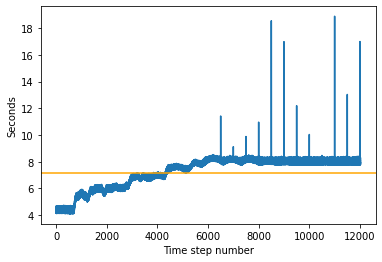

/home/thibault.derrien/Documents/octopus.data/03-Bulk3D/Si-1x1x1-k-24x24x1-Angle0.12-Mesh0.434637008855-Mesh0.434637008855-T0e0/lambda2656e-9-tau30e-15-field9E9-CEP0.0-theta0.12-SinSquared-SinPower2-2/lambda400e-9-tau30e-15-field0E0-CEP0.0-delay0e-15-SinSquared


In [14]:
import matplotlib.pyplot as plt
plt.plot(results_np[:,0], results_np[:,4])
plt.axhline(np.mean(results_np[:,4]), color="orange")
plt.xlabel("Time step number")
plt.ylabel("Seconds")
plt.savefig("DurationOfTimeStep.eps")
plt.show()
!pwd

# Fetch number of processes for this run

In [20]:
libString.LookUpStringInFile(file, "processes").strip().split()[4]

'384'